# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [3]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [5]:
display(df.head())
print('Розмір датасету:', df.shape)
print('Інформація про стовпці:')
df.info()


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету: (2338, 14)
Інформація про стовпці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
print('Пропуски:')
display(df.isnull().sum().to_frame('Кількість пропусків'))
print('Кількість дублікатів:', df.duplicated().sum())


Пропуски:


,Кількість пропусків
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Кількість дублікатів: 0


In [7]:
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
У датасеті 2338 рядків і 14 стовпців: 13 числових ознак та цільова змінна Cured. У наданому файлі пропущених значень і повних дублікатів немає. Отже, дані повні та мають числовий формат, придатний для подальшої класифікації.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Навчальна вибірка:', X_train.shape, y_train.shape)
print('Тестова вибірка:', X_test.shape, y_test.shape)

Навчальна вибірка: (1870, 13) (1870,)
Тестова вибірка: (468, 13) (468,)


### 5. Баланс класів на навчальній вибірці

In [9]:
print('Кількість кожного класу:')
display(y_train.value_counts().sort_index().to_frame('Кількість'))
print('Частка кожного класу:')
display(y_train.value_counts(normalize=True).sort_index().to_frame('Частка'))

Кількість кожного класу:


,Кількість
Cured,
0,946
1,924


Частка кожного класу:


,Частка
Cured,
0,0.505882
1,0.494118


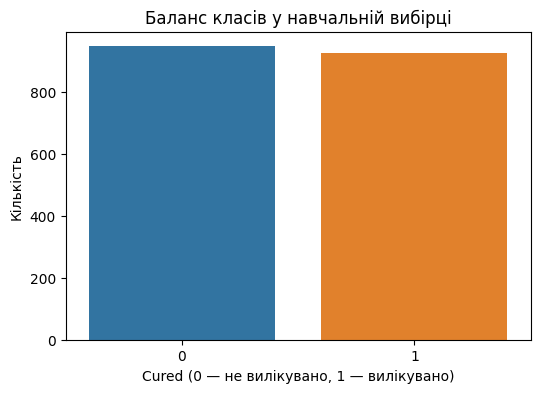

In [10]:
plot_data = pd.DataFrame({'Cured': y_train})
plt.figure(figsize=(6, 4))
sns.countplot(data=plot_data, x='Cured', hue='Cured', legend=False)
plt.title('Баланс класів у навчальній вибірці')
plt.xlabel('Cured (0 — не вилікувано, 1 — вилікувано)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
Класи представлені майже порівну: це означає, що навчальна вибірка є практично збалансованою. Через це модель не має значної переваги у прогнозуванні лише одного класу.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

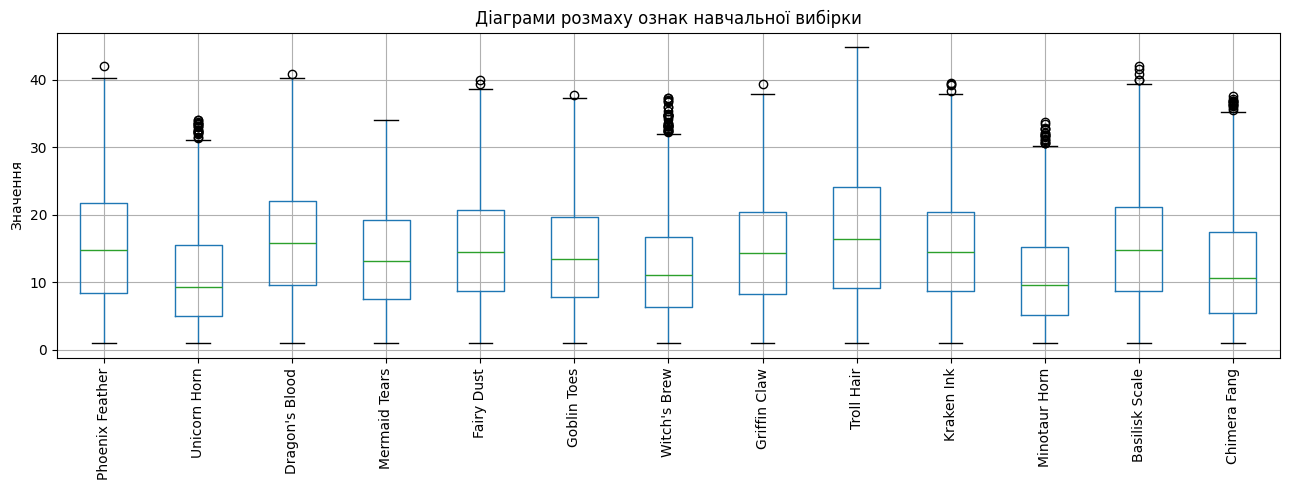

In [11]:
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title('Діаграми розмаху ознак навчальної вибірки')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [12]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_counts = ((X_train < lower) | (X_train > upper)).sum()
outlier_counts = outlier_counts.sort_values(ascending=False)
display(outlier_counts.to_frame('Кількість потенційних викидів'))
print('Ознака з найбільшою кількістю потенційних викидів:', outlier_counts.index[0])

,Кількість потенційних викидів
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


Ознака з найбільшою кількістю потенційних викидів: Witch's Brew


**Висновок про викиди:**  
Таблиця показує кількість потенційних викидів для кожної ознаки за правилом 1,5 IQR. Найбільше їх у ознаці, яка стоїть першою у відсортованій таблиці. Викиди не видаляємо автоматично: вони можуть бути реальними значеннями характеристик інгредієнтів, а видалення здатне призвести до втрати важливої інформації.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

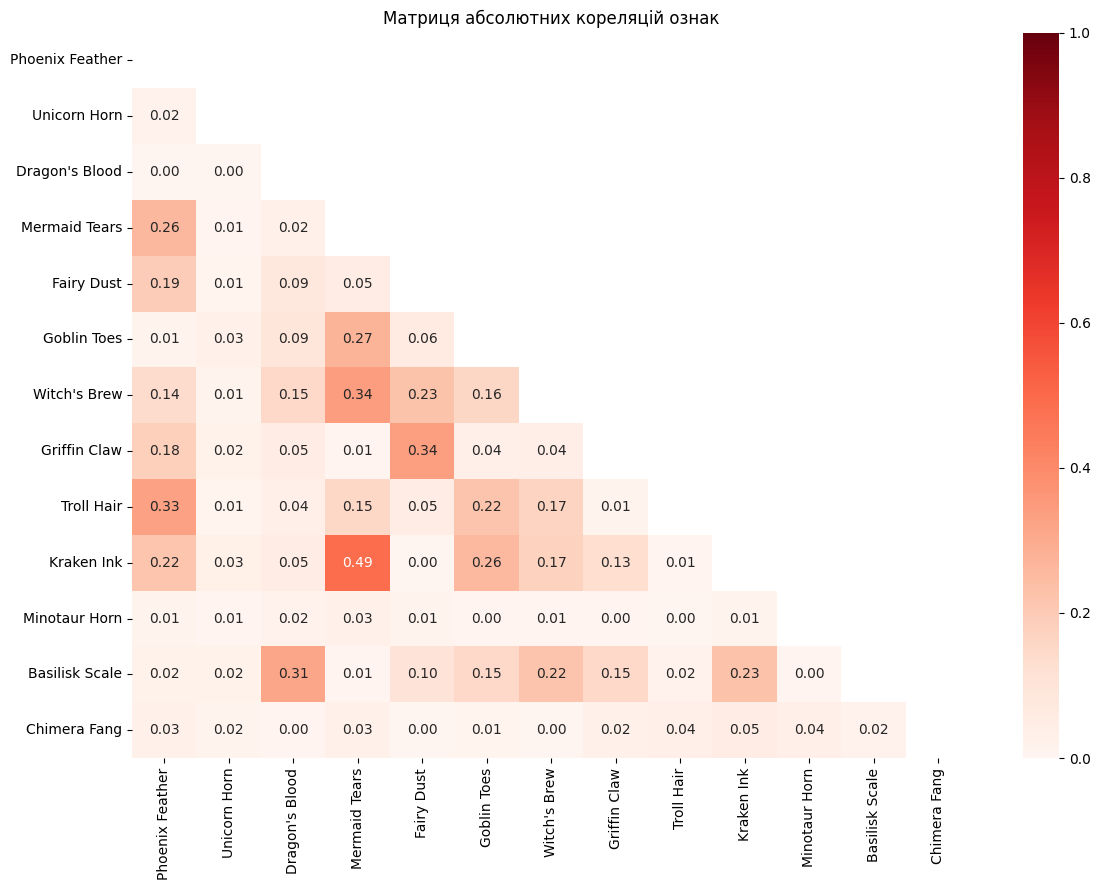

In [13]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Матриця абсолютних кореляцій ознак')
plt.tight_layout()
plt.show()

In [14]:
corr_with_target = pd.concat([X_train, y_train.rename('Cured')], axis=1).corr()['Cured'].drop('Cured')
corr_with_target = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)
display(corr_with_target.to_frame('Кореляція з Cured'))
print('Найсильніший зв’язок із Cured має ознака:', corr_with_target.abs().idxmax())

,Кореляція з Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


Найсильніший зв’язок із Cured має ознака: Troll Hair


**Висновок про кореляції:**  
У тепловій карті значення, ближчі до 1, означають сильніший зв’язок між ознаками. У таблиці кореляцій із Cured найбільший зв’язок має ознака, зазначена першою за модулем. Кореляція не доводить причинно-наслідковий зв’язок, а лише показує лінійну залежність.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Розмір стандартизованого X_train:', X_train_scaled.shape)
print('Розмір стандартизованого X_test:', X_test_scaled.shape)

Розмір стандартизованого X_train: (1870, 13)
Розмір стандартизованого X_test: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [16]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('\nДетальний звіт:')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8931623931623932

Детальний звіт:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

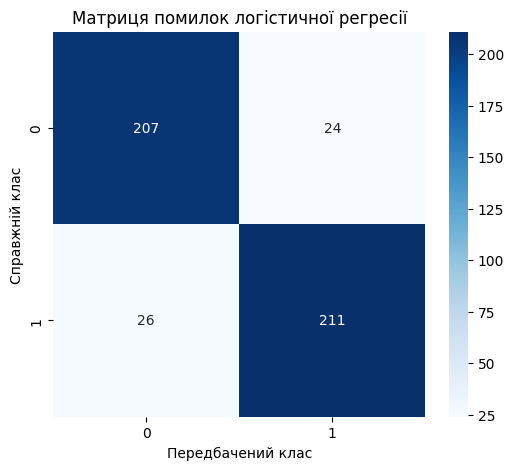

In [17]:
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок логістичної регресії')
plt.show()

In [18]:
predictions = pd.DataFrame({
    'Справжній клас': y_test,
    'Передбачений клас': y_pred
})
display(predictions.sample(10, random_state=42))


,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
За матрицею помилок можна побачити, скільки разів модель правильно та неправильно визначила кожен клас. Значення поза головною діагоналлю — це помилки. Accuracy показує загальну частку правильних прогнозів, але не показує характер помилок, тому додатково аналізуємо precision, recall і F1-score.


### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [19]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [500, 1000]
}
param_dist = {
    'C': np.logspace(-3, 2, 30),
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [500, 1000, 1500]
}

In [20]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid, cv=3, scoring='accuracy', n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)
print('Найкращі параметри GridSearchCV:', grid_search.best_params_)
print('Найкраща CV Accuracy:', grid_search.best_score_)

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
Найкраща CV Accuracy: 0.8673927508197171


In [21]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_dist, n_iter=20, cv=3, scoring='accuracy',
    random_state=42, n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)
print('Найкращі параметри RandomizedSearchCV:', random_search.best_params_)
print('Найкраща CV Accuracy:', random_search.best_score_)

Найкращі параметри RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 1000, 'C': np.float64(20.43359717856944)}
Найкраща CV Accuracy: 0.8673927508197171


In [22]:
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    selected_search = 'GridSearchCV'
else:
    best_model = random_search.best_estimator_
    selected_search = 'RandomizedSearchCV'

best_pred = best_model.predict(X_test_scaled)
print('Обраний метод:', selected_search)
print('Accuracy після підбору:', accuracy_score(y_test, best_pred))
print('\nДетальний звіт:')
print(classification_report(y_test, best_pred, zero_division=0))

Обраний метод: GridSearchCV
Accuracy після підбору: 0.8931623931623932

Детальний звіт:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
GridSearchCV перевіряє всі комбінації з визначеної сітки, а RandomizedSearchCV — випадково вибрану кількість комбінацій. Порівнюємо їхню найкращу середню Accuracy на крос-валідації та тестову Accuracy обраної моделі з базовою логістичною регресією.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [23]:
models = {
    'Логістична регресія': model,
    'SVC': SVC(),
    'Дерево рішень': DecisionTreeClassifier(random_state=42)
}
results = []

for name, estimator in models.items():
    estimator.fit(X_train_scaled, y_train)
    pred = estimator.predict(X_test_scaled)
    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'F1-score': f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values('F1-score', ascending=False)
display(results_df)
print('Найкраща модель за F1-score:', results_df.iloc[0]['Модель'])

,Модель,Accuracy,F1-score
1,SVC,0.959402,0.960000
0,Логістична регресія,0.893162,0.894068
2,Дерево рішень,0.865385,0.865672


Найкраща модель за F1-score: SVC


### 13. Висновки до лабораторної роботи

1. Під час первинного аналізу було встановлено, що датасет містить 2338 рядків і 14 стовпців, з яких 13 — ознаки, а один — цільова змінна Cured. Пропущених значень і дублікатів не виявлено. Навчальна вибірка містить 1870 записів, тестова — 468. Розподіл класів майже збалансований: 946 записів класу 0 та 924 записи класу 1.

2. Дослідження викидів на навчальній вибірці за правилом 1,5 IQR показало, що найбільше потенційних викидів міститься в ознаці Witch's Brew — 33, Unicorn Horn — 20 та Minotaur Horn — 18. Під час кореляційного аналізу було встановлено, що найсильніший зв'язок із цільовою змінною Cured має ознака Troll Hair (0,489), а також Witch's Brew (0,247). Це свідчить про те, що ці характеристики мають найбільший лінійний зв'язок із результатом лікування серед досліджених ознак.

3. Базова логістична регресія показала Accuracy 89,32%, а F1-score — 89,41%. Precision та Recall для обох класів становили приблизно 0,89–0,90. Отже, модель продемонструвала досить високу якість класифікації та добре розпізнавала обидва класи.

4. Підбір гіперпараметрів за допомогою GridSearchCV та RandomizedSearchCV не призвів до покращення Accuracy на тестовій вибірці. Найкращими параметрами GridSearchCV стали C=10, max_iter=500, solver='lbfgs'. Після підбору Accuracy залишилася на рівні 89,32%, тобто такою самою, як у базової моделі. Отже, у цьому випадку підбір параметрів не дав помітного покращення якості прогнозування.

5. Під час порівняння трьох моделей найкращий результат показала SVC з Accuracy 95,94% та F1-score 96,00%. Логістична регресія отримала Accuracy 89,32% та F1-score 89,41%, а дерево рішень — Accuracy 86,54% та F1-score 86,57%. Таким чином, SVC виявилася найефективнішою моделлю серед трьох досліджених алгоритмів.


**Ваші висновки:**  
Під час лабораторної роботи я навчилася проводити первинний аналіз даних, досліджувати викиди та кореляції, розділяти дані на навчальну й тестову вибірки, виконувати стандартизацію та будувати моделі машинного навчання. Також я навчилася оцінювати якість класифікації за різними метриками, підбирати гіперпараметри та порівнювати алгоритми. За результатами дослідження найкращою моделлю для цього датасету виявилася SVC.